# Week 2: exploratory analysis

**Where unaccompanied children are released to sponsors, FY2015–FY2025.** Five findings, each backed by a
chart. Service planning only: counts describe the communities' service needs (schools, legal aid, case
management), not the communities.

**Guardrails.** Public, aggregate data only. Counties appear only for years with 50 or more releases (ORR's
threshold); all other counties in a state are one "other counties" group and are never split or estimated.

**Data.** Migration Policy Institute tabulation of ACF/ORR data (`data/raw/mpi/`), reshaped in Week 1
(`data/processed/releases_by_fy_geo.parquet`); Census Bureau Vintage 2024 population and 2023 cartographic
boundary files (`data/raw/geo/`). Fiscal years run October to September.

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Works whether the notebook is opened from notebooks/ or from the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
FY = list(range(2015, 2026))
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8bcc2"
# House style for every chart: Arial, no top/right borders, light grid behind the data.
plt.rcParams.update({"font.family": "Arial", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c3", "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True})

df = pd.read_parquet(ROOT / "data/processed/releases_by_fy_geo.parquet")
df = df[df["fiscal_year"].isin(FY)].copy()
# FIPS codes back to 5-digit text: drop a trailing '.0' and restore leading zeros (1001 -> 01001).
df["county_fips"] = df["county_fips"].astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(5)
# Split the table by level once; every finding below reuses these four tables.
nat = df[df.geo_level == "national"].set_index("fiscal_year")["releases"]
states = df[(df.geo_level == "state") & ~df.state.isin(["PR", "VI"])]
counties = df[df.geo_level == "county"]
other = df[df.geo_level == "other_counties"]
findings = []
def save(fig, name):  # tidy the layout, save a PNG for the report, show the chart here
    fig.tight_layout(); fig.savefig(FIG / f"week2_{name}.png", dpi=200, facecolor="white"); plt.show()
print(f"{len(df):,} rows; FY{FY[0]}-FY{FY[-1]}; {counties.county_key.nunique()} counties listed at least once")

3,403 rows; FY2015-FY2025; 393 counties listed at least once


## 1. National releases rose to a peak in FY2022 and have since fallen sharply

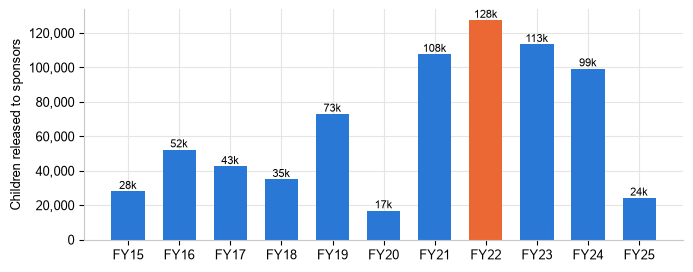

National releases ranged from 16,864 (FY2020) to 127,512 (FY2022). FY2021-FY2024 account for 62% of all FY2015-FY2025 releases; FY2025 fell to 24,259, 76% below FY2024.


In [2]:
fig, ax = plt.subplots(figsize=(7, 2.8))
peak = nat.idxmax()  # idxmax gives the label of the largest value (the year), not the value
ax.bar(nat.index, nat.values, color=[ORANGE if y == peak else BLUE for y in nat.index], width=0.65)
for y, v in nat.items():
    ax.text(y, v, f"{v/1000:.0f}k", ha="center", va="bottom", fontsize=8)
ax.set_xticks(FY, [f"FY{str(y)[2:]}" for y in FY]); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("Children released to sponsors")
save(fig, "national_by_year")
surge = [2021, 2022, 2023, 2024]
# The finding sentence is written from the data: {:,} adds thousands separators, {:.0%} formats a
# whole-number percentage.
f = (f"National releases ranged from {nat.min():,} (FY{nat.idxmin()}) to {nat.max():,} (FY{peak}). "
     f"FY2021-FY2024 account for {nat[surge].sum()/nat.sum():.0%} of all FY2015-FY2025 releases; "
     f"FY2025 fell to {nat[2025]:,}, {1 - nat[2025]/nat[2024]:.0%} below FY2024.")
findings.append(f); print(f)

## 2. The same states receive the largest shares year after year

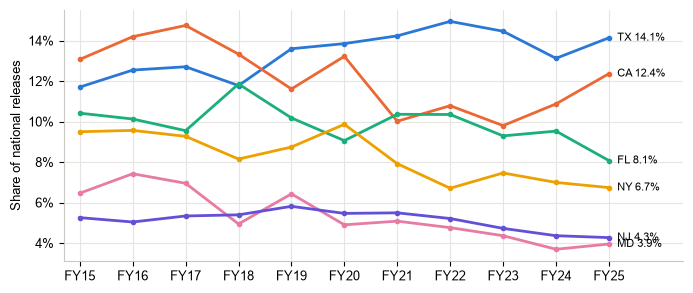

The six largest receiving states (TX, CA, FL, NY, MD, NJ) took 53% of FY2015-FY2025 releases. TX's share ranged from 11.7% to 14.9%; year-to-year state rank correlations (Week 3) never fell below 0.98.


In [3]:
tot = states.groupby("state")["releases"].sum().sort_values(ascending=False)
top = list(tot.index[:6])
share = states.pivot_table(index="fiscal_year", columns="state", values="releases", aggfunc="sum")
share = share.div(share.sum(axis=1), axis=0)  # divide each year's row by its total: counts become shares
fig, ax = plt.subplots(figsize=(7, 3))
colors = [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4", "#6250d6"]
for s, c in zip(top, colors):
    ax.plot(share.index, share[s], color=c, lw=2, marker="o", ms=3)
    ax.annotate(f"{s} {share[s].iloc[-1]:.1%}", (share.index[-1], share[s].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8)
ax.set_xticks(FY, [f"FY{str(y)[2:]}" for y in FY]); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylabel("Share of national releases"); ax.set_xlim(FY[0] - 0.3, FY[-1] + 1.4)
save(fig, "top_state_shares")
pers = pd.read_csv(ROOT / "results/persistence_state_ranks.csv")
rho_col = [c for c in pers.columns if "spearman" in c.lower()][0]  # find the Spearman column by name instead of hard-coding it
f = (f"The six largest receiving states ({', '.join(top)}) took {tot[top].sum()/tot.sum():.0%} of FY2015-FY2025 releases. "
     f"{top[0]}'s share ranged from {share[top[0]].min():.1%} to {share[top[0]].max():.1%}; year-to-year state rank "
     f"correlations (Week 3) never fell below {pers[rho_col].min():.2f}.")
findings.append(f); print(f)

## 3. A small set of counties receives the most children every year

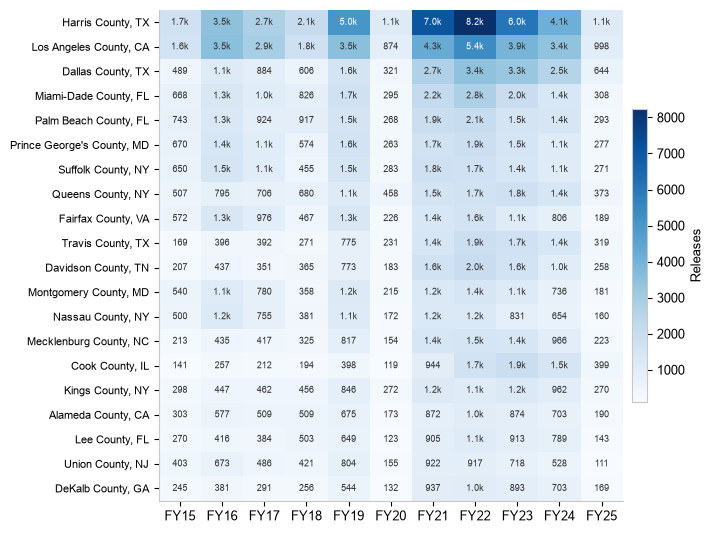

The 20 largest receiving counties took 34% of all FY2015-FY2025 releases. Harris County, TX received the most children in 9 of 11 years, and 20 of the 20 were listed (50+ releases) in every year.


In [4]:
ctot = counties.groupby(["county_key", "county_name"])["releases"].sum().sort_values(ascending=False)
top20 = ctot.head(20).reset_index()
# Heatmap table: the 20 largest counties (rows) by fiscal year (columns). A blank cell means the county
# had under 50 releases that year and was not listed; it stays blank and is never estimated.
heat = (counties[counties.county_key.isin(top20.county_key)]
        .pivot_table(index="county_name", columns="fiscal_year", values="releases", aggfunc="sum")
        .reindex(top20.county_name))
fig, ax = plt.subplots(figsize=(7.2, 5.4))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(heat.columns)), [f"FY{str(y)[2:]}" for y in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index, fontsize=8); ax.grid(False)
for (i, j), v in pd.DataFrame(heat.values).stack().items():
    ax.text(j, i, f"{v/1000:.1f}k" if v >= 1000 else f"{v:.0f}", ha="center", va="center", fontsize=6.5,
            color="white" if v > heat.values[~pd.isna(heat.values)].max() * 0.55 else "#333")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="Releases")
save(fig, "top20_counties")
leader = counties.loc[counties.groupby("fiscal_year")["releases"].idxmax(), ["fiscal_year", "county_name"]]  # the county with the most releases in each year
always = int(heat.notna().all(axis=1).sum())  # counties listed in every year
f = (f"The 20 largest receiving counties took {top20.releases.sum()/nat.sum():.0%} of all FY2015-FY2025 releases. "
     f"{leader.county_name.mode()[0]} received the most children in {(leader.county_name == leader.county_name.mode()[0]).sum()} "
     f"of {len(FY)} years, and {always} of the 20 were listed (50+ releases) in every year.")
findings.append(f); print(f)

## 4. In surge years more counties cross the 50-release threshold

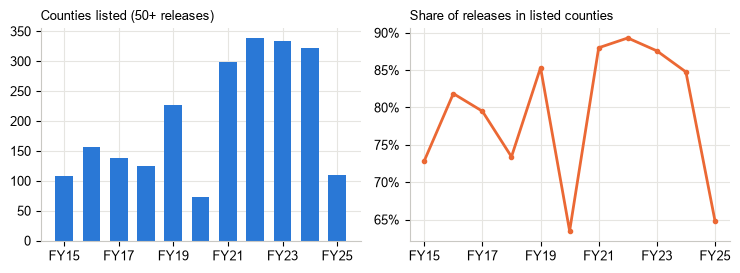

Listed counties ranged from 73 (FY2020) to 338 (FY2022). They held 63%-89% of releases; the rest went to the unlisted 'other counties' group, which is not split further.


In [5]:
listed = counties.groupby("fiscal_year").agg(listed_releases=("releases", "sum"), listed_counties=("county_key", "nunique"))
listed["other_releases"] = other.groupby("fiscal_year")["releases"].sum()
listed["listed_share"] = listed.listed_releases / (listed.listed_releases + listed.other_releases)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 2.8))
a1.bar(listed.index, listed.listed_counties, color=BLUE, width=0.65)
a1.set_title("Counties listed (50+ releases)", fontsize=9, loc="left"); a1.set_xticks(FY[::2], [f"FY{str(y)[2:]}" for y in FY[::2]])
a2.plot(listed.index, listed.listed_share, color=ORANGE, lw=2, marker="o", ms=3)
a2.set_title("Share of releases in listed counties", fontsize=9, loc="left"); a2.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
a2.set_xticks(FY[::2], [f"FY{str(y)[2:]}" for y in FY[::2]])
save(fig, "listed_vs_other")
lo, hi = listed.listed_counties.idxmin(), listed.listed_counties.idxmax()
f = (f"Listed counties ranged from {listed.listed_counties.min()} (FY{lo}) to {listed.listed_counties.max()} (FY{hi}). "
     f"They held {listed.listed_share.min():.0%}-{listed.listed_share.max():.0%} of releases; the rest went to the "
     f"unlisted 'other counties' group, which is not split further.")
findings.append(f); print(f)

## 5. Maps: where children were released, in total and per school-age child

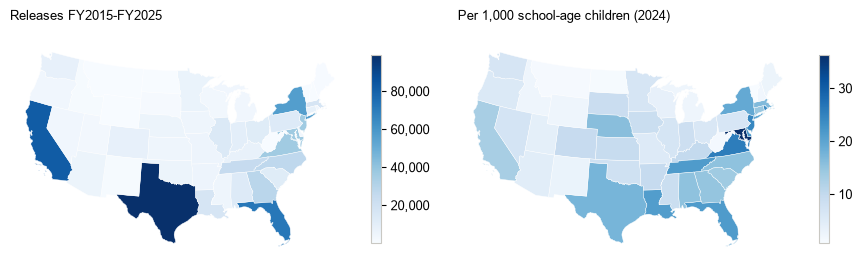

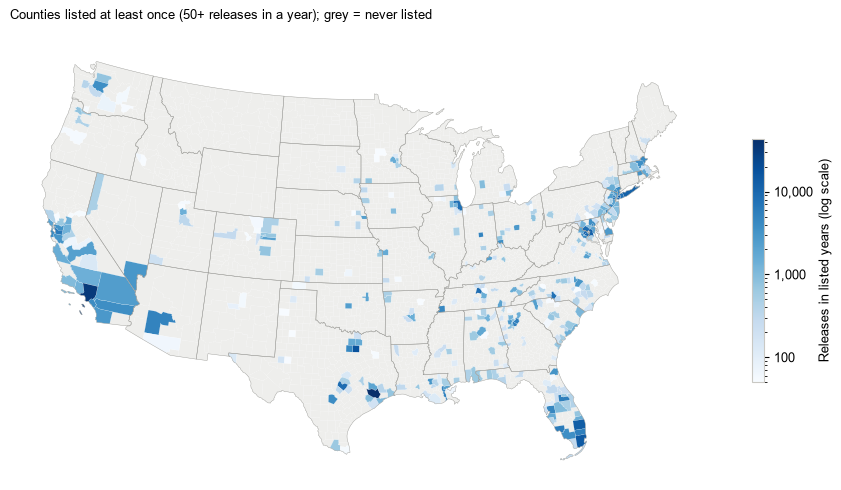

Per school-age child, the highest totals were in MD, DC, VA (36 per 1,000), the lowest in HI, VT, AK. 393 counties were listed at least once; 389 appear on the county map (4 Connecticut counties have no FIPS match because the 2023 boundaries use planning regions; Alaska, Hawaii and Puerto Rico are left off the maps).


In [6]:
geo = ROOT / "data/raw/geo"
# geopandas reads map shapes straight from the zipped Census files; to_crs(5070) switches to an
# equal-area projection so states are drawn at their true relative size.
st_shp = gpd.read_file(f"zip://{geo / 'cb_2023_us_state_20m.zip'}").to_crs(5070)
co_shp = gpd.read_file(f"zip://{geo / 'cb_2023_us_county_20m.zip'}").to_crs(5070)
lower48 = lambda g: g[~g.STUSPS.isin(["AK", "HI", "PR"])]  # leave Alaska, Hawaii and Puerto Rico off the maps
st_tot = states.groupby("state").agg(releases=("releases", "sum"), pop_5_17=("pop_5_17_2024", "first")).reset_index()
st_tot["per_1000_school_age"] = 1000 * st_tot.releases / st_tot.pop_5_17  # releases relative to school-age population: a service-planning rate (schools)
m = lower48(st_shp).merge(st_tot, left_on="STUSPS", right_on="state", how="left")  # join map shapes to the numbers by state code; how='left' keeps every state on the map
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col, title in ((axes[0], "releases", "Releases FY2015-FY2025"),
                       (axes[1], "per_1000_school_age", "Per 1,000 school-age children (2024)")):
    m.plot(column=col, cmap="Blues", linewidth=0.3, edgecolor="white", ax=ax, legend=True,
           legend_kwds={"shrink": 0.6, "format": mtick.FuncFormatter(lambda v, _: f"{v:,.0f}")})
    ax.set_title(title, fontsize=9, loc="left"); ax.set_axis_off()
save(fig, "state_maps")

cty = counties.groupby("county_fips").agg(releases=("releases", "sum"), years=("fiscal_year", "nunique")).reset_index()
cm = lower48(co_shp).merge(cty, left_on="GEOID", right_on="county_fips", how="left")
fig, ax = plt.subplots(figsize=(9, 5.2))
cm[cm.releases.isna()].plot(color="#eeeeec", linewidth=0.05, edgecolor="white", ax=ax)  # never-listed counties are drawn plain grey: no count is shown or estimated for them
from matplotlib.colors import LogNorm  # log color scale, so 50 and 50,000 both fit on one legend
cm[cm.releases.notna()].plot(column="releases", cmap="Blues", norm=LogNorm(vmin=50, vmax=cm.releases.max()),
                              linewidth=0.1, edgecolor="white", ax=ax,
                              legend=True, legend_kwds={"shrink": 0.5, "label": "Releases in listed years (log scale)",
                                                         "format": mtick.FuncFormatter(lambda v, _: f"{v:,.0f}")})
lower48(st_shp).boundary.plot(ax=ax, color="#9a9a96", linewidth=0.3)
ax.set_axis_off(); ax.set_title("Counties listed at least once (50+ releases in a year); grey = never listed", fontsize=9, loc="left")
save(fig, "county_map")
st_rank = st_tot.sort_values("per_1000_school_age", ascending=False)
f = (f"Per school-age child, the highest totals were in {', '.join(st_rank.state.head(3))} "
     f"({st_rank.per_1000_school_age.head(1).iloc[0]:.0f} per 1,000), the lowest in {', '.join(st_rank.state.tail(3))}. "
     f"{counties.county_key.nunique()} counties were listed at least once; {(cm.releases.notna()).sum()} appear on the "
     f"county map ({(counties.county_fips.isna() | (counties.county_fips == '<NA>')).groupby(counties.county_key).any().sum()} "
     f"Connecticut counties have no FIPS match because the 2023 boundaries use planning regions; Alaska, Hawaii and "
     f"Puerto Rico are left off the maps).")
findings.append(f); print(f)

## Summary of findings

In [7]:
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}\n")

1. National releases ranged from 16,864 (FY2020) to 127,512 (FY2022). FY2021-FY2024 account for 62% of all FY2015-FY2025 releases; FY2025 fell to 24,259, 76% below FY2024.

2. The six largest receiving states (TX, CA, FL, NY, MD, NJ) took 53% of FY2015-FY2025 releases. TX's share ranged from 11.7% to 14.9%; year-to-year state rank correlations (Week 3) never fell below 0.98.

3. The 20 largest receiving counties took 34% of all FY2015-FY2025 releases. Harris County, TX received the most children in 9 of 11 years, and 20 of the 20 were listed (50+ releases) in every year.

4. Listed counties ranged from 73 (FY2020) to 338 (FY2022). They held 63%-89% of releases; the rest went to the unlisted 'other counties' group, which is not split further.

5. Per school-age child, the highest totals were in MD, DC, VA (36 per 1,000), the lowest in HI, VT, AK. 393 counties were listed at least once; 389 appear on the county map (4 Connecticut counties have no FIPS match because the 2023 boundaries us